# Beyond the Flood Warning: analysis pipeline

**Purpose.** This notebook runs the whole analysis behind our poster and reports, from the raw data to every number we quote, and shows the results in the order of the poster. It answers: what changed in the flood dynamics, which indicators give useful warnings, and what do missed floods and false alarms cost.

**How to use it.**
1. Install the packages in `requirements.txt` (see `README.md`).
2. Keep this notebook in the same folder as `flood_drivers/`, `processing_data/` and `raw_data/`.
3. Set `RUN_PIPELINE` below. `True` re-runs every step from the raw data. `False` only displays the results already stored in `flood_drivers/results/`.
4. Run all cells (Run All).

The heavy work is done by the scripts in `flood_drivers/`, one file per task. This notebook calls them in order and then reads their output tables.

In [1]:
import sys, subprocess, importlib.metadata as metadata
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

RUN_PIPELINE = True        # False = only show the stored results (fast)

ROOT = Path.cwd()
if not (ROOT / "flood_drivers").exists():
    ROOT = ROOT.parent     # allow the notebook to sit in a sub-folder
RESULTS = ROOT / "flood_drivers" / "results"
V2 = RESULTS / "v2"
AREA = {"ext_ayod": "Ayod", "ext_bor_south": "Bor South", "ext_malakal": "Malakal", "q_mean": "River discharge"}
print("Project root:", ROOT, "| Python", sys.version.split()[0])

Project root: c:\Users\20242408\OneDrive - TU Eindhoven\Documenten\DATA SCIENCE BACHELOR\Jaar 3\Q1\Capstone data challenge\JBG060_ZHL_2026 | Python 3.12.7


## 0. Environment and input check

In [2]:
packages = ["numpy", "pandas", "scipy", "scikit-learn", "xarray", "netCDF4", "geopandas", "shapely",
            "matplotlib", "plotly", "streamlit", "openpyxl", "tqdm", "joblib"]
for name in packages:
    try:
        print(f"{name:14s}{metadata.version(name)}")
    except metadata.PackageNotFoundError:
        print(f"{name:14s}NOT INSTALLED")

raw = ROOT / "raw_data"
required = {
    "Dartmouth discharge": raw / "Darthmouth Flood Observatory" / "information.xlsx",
    "Lake levels": raw / "Water levels lakes",
    "ERA5 rainfall and runoff": raw / "rainfall and runoff",
    "Flood masks": raw / "flood_masks",
    "Administrative boundaries": raw / "Administrative boundaries" / "ssd_admin2.geojson",
    "Course loader": ROOT / "processing_data" / "loading.py",
}
for label, path in required.items():
    print(f"{'ok     ' if path.exists() else 'MISSING'} {label}: {path.relative_to(ROOT)}")
hybas = sorted(raw.rglob("hybas_af_lev06*.shp")) if raw.exists() else []
print("ok      HydroBASINS:" if hybas else "MISSING HydroBASINS (the run falls back to boxes only):", hybas[0].name if hybas else "")

numpy         2.4.6
pandas        3.0.3
scipy         1.17.1
scikit-learn  1.9.1
xarray        2026.4.0
netCDF4       1.7.4
geopandas     1.1.4
shapely       2.1.2
matplotlib    3.10.9
plotly        6.9.0
streamlit     NOT INSTALLED
openpyxl      3.1.5
tqdm          4.68.3
joblib        1.5.3
ok      Dartmouth discharge: raw_data\Darthmouth Flood Observatory\information.xlsx
ok      Lake levels: raw_data\Water levels lakes
ok      ERA5 rainfall and runoff: raw_data\rainfall and runoff
ok      Flood masks: raw_data\flood_masks
ok      Administrative boundaries: raw_data\Administrative boundaries\ssd_admin2.geojson
ok      Course loader: processing_data\loading.py
ok      HydroBASINS: hybas_af_lev06_v1c.shp


## 1. Run the pipeline

| Step | Script | What it does | Main output |
|---|---|---|---|
| 1 | `build_dataset.py` | Reads the raw data and builds one monthly table | `processing_data/flood_drivers/monthly_dataset.csv` |
| 2 | `analyse.py` | Lag correlations and driver importance | `flood_drivers/results/` |
| 3 | `analyse_v2.py` | Regime summary, forecasts and skill scores, expanding-window test | `results/v2/regime_summary.csv`, `skill_v2.csv`, `predictions_v2.csv` |
| 4 | `indicator_impact.py` | Do lake and rain indicators help equally in every area? | `results/v2/indicator_impact.csv` |
| 5 | `sle_risk_test.py` | Missed floods versus false alarms, with uncertainty ranges | `results/v2/sle_*.csv` |
| 6 | `make_poster_figures.py` | Poster figure of misses versus false alarms | `results/v2/poster_figures/` |

In [3]:
STEPS = ["build_dataset.py", "analyse.py", "analyse_v2.py", "indicator_impact.py", "sle_risk_test.py", "make_poster_figures.py"]

def run_step(script):
    """Run one pipeline script from the project root and stop with its error message if it fails."""
    print(f"--- {script}")
    result = subprocess.run([sys.executable, str(ROOT / "flood_drivers" / script)],
                            cwd=ROOT, capture_output=True, text=True)
    print(result.stdout[-1200:])
    if result.returncode != 0:
        print(result.stderr[-3000:])
        raise RuntimeError(f"{script} failed (see the message above)")

if RUN_PIPELINE:
    for script in STEPS:
        run_step(script)
else:
    print("RUN_PIPELINE is False: showing stored results only.")

def read(name, **kwargs):
    """Read one result table from flood_drivers/results/v2."""
    path = V2 / name
    if not path.exists():
        raise FileNotFoundError(f"{name} not found. Set RUN_PIPELINE = True, or copy the results folder next to this notebook.")
    return pd.read_csv(path, **kwargs)

--- build_dataset.py
g           288.0    30.05     3.23    98.59
rain_bahr_jebel       288.0    90.31     0.03   237.37
ro_bahr_jebel         288.0    13.26     0.82    50.31
rain_bahr_ghazal      288.0    69.32     0.00   261.64
ro_bahr_ghazal        288.0     3.02     0.06    29.80
rain_sobat            288.0   105.71     1.51   261.86
ro_sobat              288.0    34.41     2.25   102.67
rain_local_ayod       288.0    67.97     0.00   248.64
ro_local_ayod         288.0     2.91     0.00    29.10
rain_local_bor_south  288.0    72.51     0.00   258.24
ro_local_bor_south    288.0     2.71     0.00    33.35
rain_local_malakal    288.0    52.90     0.00   262.40
ro_local_malakal      288.0     1.96     0.00    24.82
ext_ayod              288.0     0.01     0.00     0.08
extunusual_ayod       288.0     0.01     0.00     0.07
obs_ayod              288.0    21.97     0.00    31.00
ext_bor_south         288.0     0.00     0.00     0.08
extunusual_bor_south  288.0     0.00     0.00     0.08

## 2. What changed in the flood dynamics (poster section 01)

The regime summary finds, for each annual series, the single year that best splits it into a before and an after mean. `ratio_after_before` is the "x15, x38, x2.7" in the poster. The split year is estimated per series, so check `split_year` when quoting the numbers.

,series,split_year,mean_before,mean_after,ratio_after_before,variance_explained_by_step
0,q_mean,2021,5541.165,4769.146,0.861,0.858
1,ext_ayod,2021,0.002,0.023,14.691,0.791
2,ext_bor_south,2021,0.001,0.004,2.658,0.213
3,ext_malakal,2021,0.000,0.007,37.861,0.591
4,lake_victoria,2020,1135.475,1136.851,1.001,0.694
5,lake_kyoga,2020,1033.349,1035.095,1.002,0.640
6,lake_albert,2020,621.646,623.744,1.003,0.803


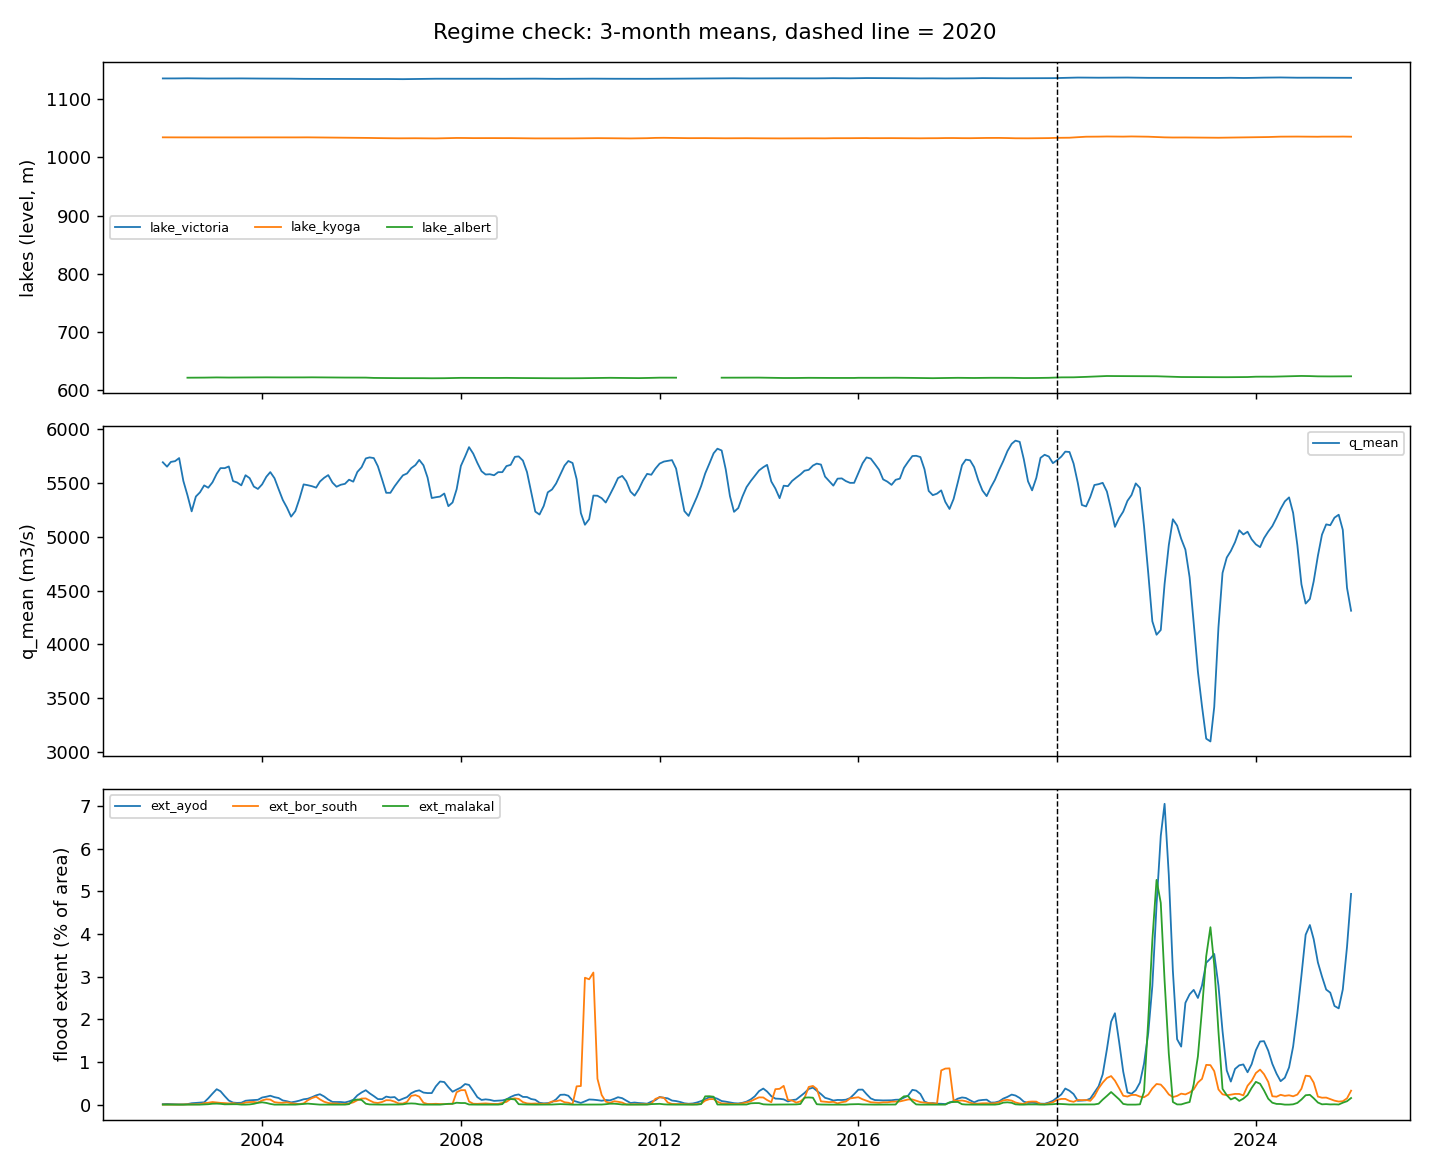

In [4]:
regime = read("regime_summary.csv")
display(regime.round(3))
fig_path = V2 / "fig_regimes.png"
if fig_path.exists():
    display(Image(filename=str(fig_path)))

## 3. Which indicators provide useful warnings (poster section 02, Table 1 and Figure 2)

Gain = how much smaller the forecast error becomes when an indicator is added to an area's own history. `lo` and `hi` give a 95% range from resampling whole test years. A range that includes 0 means no clear gain.

Error reduction (%), all test years, all lead times together:


featureset,ar+lake,ar+rain,ar+lake+rain,ar+lakechg
area,,,,
Ayod,20.0,5.0,28.0,-6.0
Bor South,3.0,-1.0,-3.0,1.0
Malakal,3.0,1.0,3.0,-3.0
River discharge,18.0,8.0,31.0,-1.0


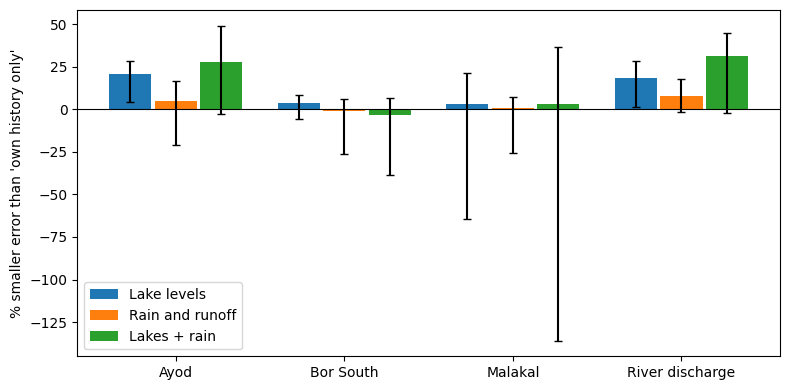

Do areas respond differently to lake levels? (95% range of the difference in gain)


,period,featureset,area_a,area_b,gain_a,gain_b,diff,lo,hi,p_value
0,all,ar+lake,ext_ayod,ext_bor_south,0.199,0.029,0.176,0.029,0.282,0.020
1,all,ar+lake,ext_ayod,ext_malakal,0.199,-0.036,0.164,0.004,0.873,0.048
2,all,ar+lake,ext_ayod,q_mean,0.199,0.175,0.028,-0.067,0.093,0.438
3,all,ar+lake,ext_bor_south,ext_malakal,0.029,-0.036,0.002,-0.206,0.684,0.982
4,all,ar+lake,ext_bor_south,q_mean,0.029,0.175,-0.150,-0.270,-0.003,0.046
5,all,ar+lake,ext_malakal,q_mean,-0.036,0.175,-0.138,-0.893,0.026,0.123


In [5]:
impact = read("indicator_impact.csv")
pooled = impact[(impact.period == "all") & (impact.lead == "all")].copy()
pooled["area"] = pooled.target.map(AREA)
table = pooled.pivot_table(index="area", columns="featureset", values="gain").mul(100).round(0)
print("Error reduction (%), all test years, all lead times together:")
display(table[["ar+lake", "ar+rain", "ar+lake+rain", "ar+lakechg"]])

fig, ax = plt.subplots(figsize=(8, 4))
order = [a for a in ["Ayod", "Bor South", "Malakal", "River discharge"] if a in set(pooled.area)]
for i, (fs, label) in enumerate([("ar+lake", "Lake levels"), ("ar+rain", "Rain and runoff"), ("ar+lake+rain", "Lakes + rain")]):
    g = pooled[pooled.featureset == fs].set_index("area").reindex(order)
    x = np.arange(len(order)) + (i - 1) * 0.27
    ax.bar(x, g.gain * 100, width=0.25, label=label,
           yerr=[(g.gain - g.lo) * 100, (g.hi - g.gain) * 100], capsize=3)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(range(len(order)), order)
ax.set_ylabel("% smaller error than 'own history only'")
ax.legend()
fig.tight_layout()
plt.show()

print("Do areas respond differently to lake levels? (95% range of the difference in gain)")
het = read("indicator_heterogeneity.csv")
display(het[(het.period == "all") & (het.featureset == "ar+lake")].round(3))

## 4. Why forecast errors matter (poster section 03)

A **flood event** is a month in the top 20% of that area's flood extent. A **missed flood** is a flood without an alert, and a **false alarm** is an alert without a flood. The alert level is fixed: an alert is issued when the forecast exceeds the flood threshold. We compare the forecast model (`ar+lake`) with simple rules.

In [6]:
conf = read("sle_confusion.csv")
one_month = conf[conf.lead == 1].copy()
one_month["area"] = one_month.target.map(AREA)
rates = one_month.pivot_table(index="area", columns="method", values=["miss_rate", "false_alarm_rate"]).mul(100).round(0)
print("Table 1 rows 'Floods missed' and 'False alarms' at 1 month ahead (%):")
display(rates)

Table 1 rows 'Floods missed' and 'False alarms' at 1 month ahead (%):


false_alarm_rate                           \
method           model (ar+lake) rule: 12-mo mean anomaly   
area                                                        
Ayod                         5.0                      6.0   
Bor South                   10.0                     26.0   
Malakal                     10.0                     12.0   
River discharge              1.0                      5.0   

                                                                    \
method          rule: last anomaly persists rule: seasonal average   
area                                                                 
Ayod                                    1.0                    0.0   
Bor South                              13.0                    1.0   
Malakal                                 8.0                    3.0   
River discharge                         7.0                    5.0   

                      miss_rate                           \
method          model (ar+lake) rule: 12-mo mean anomaly   
area                                                       
Ayod                       23.0                     23.0   
Bor South                  69.0                     31.0   
Malakal                    34.0                     16.0   
River discharge            67.0                     49.0   

                                                                    
method          rule: last anomaly persists rule: seasonal average  
area                                                                
Ayod                                   10.0                  100.0  
Bor South                              31.0                   97.0  
Malakal                                26.0                   50.0  
River discharge                        31.0                   59.0

Overall: 427 missed floods vs 200 false alarms; 68% of wrong forecasts are misses (95% range 49% to 90%).


,FN,FP,miss_share,lo,hi,false_alarm_share
scope,,,,,,
Ayod,75,40,0.65,0.00,1.00,0.35
Bor South,150,61,0.71,0.42,0.97,0.29
Malakal,66,86,0.43,0.16,0.86,0.57
River discharge,136,13,0.91,0.82,0.97,0.09


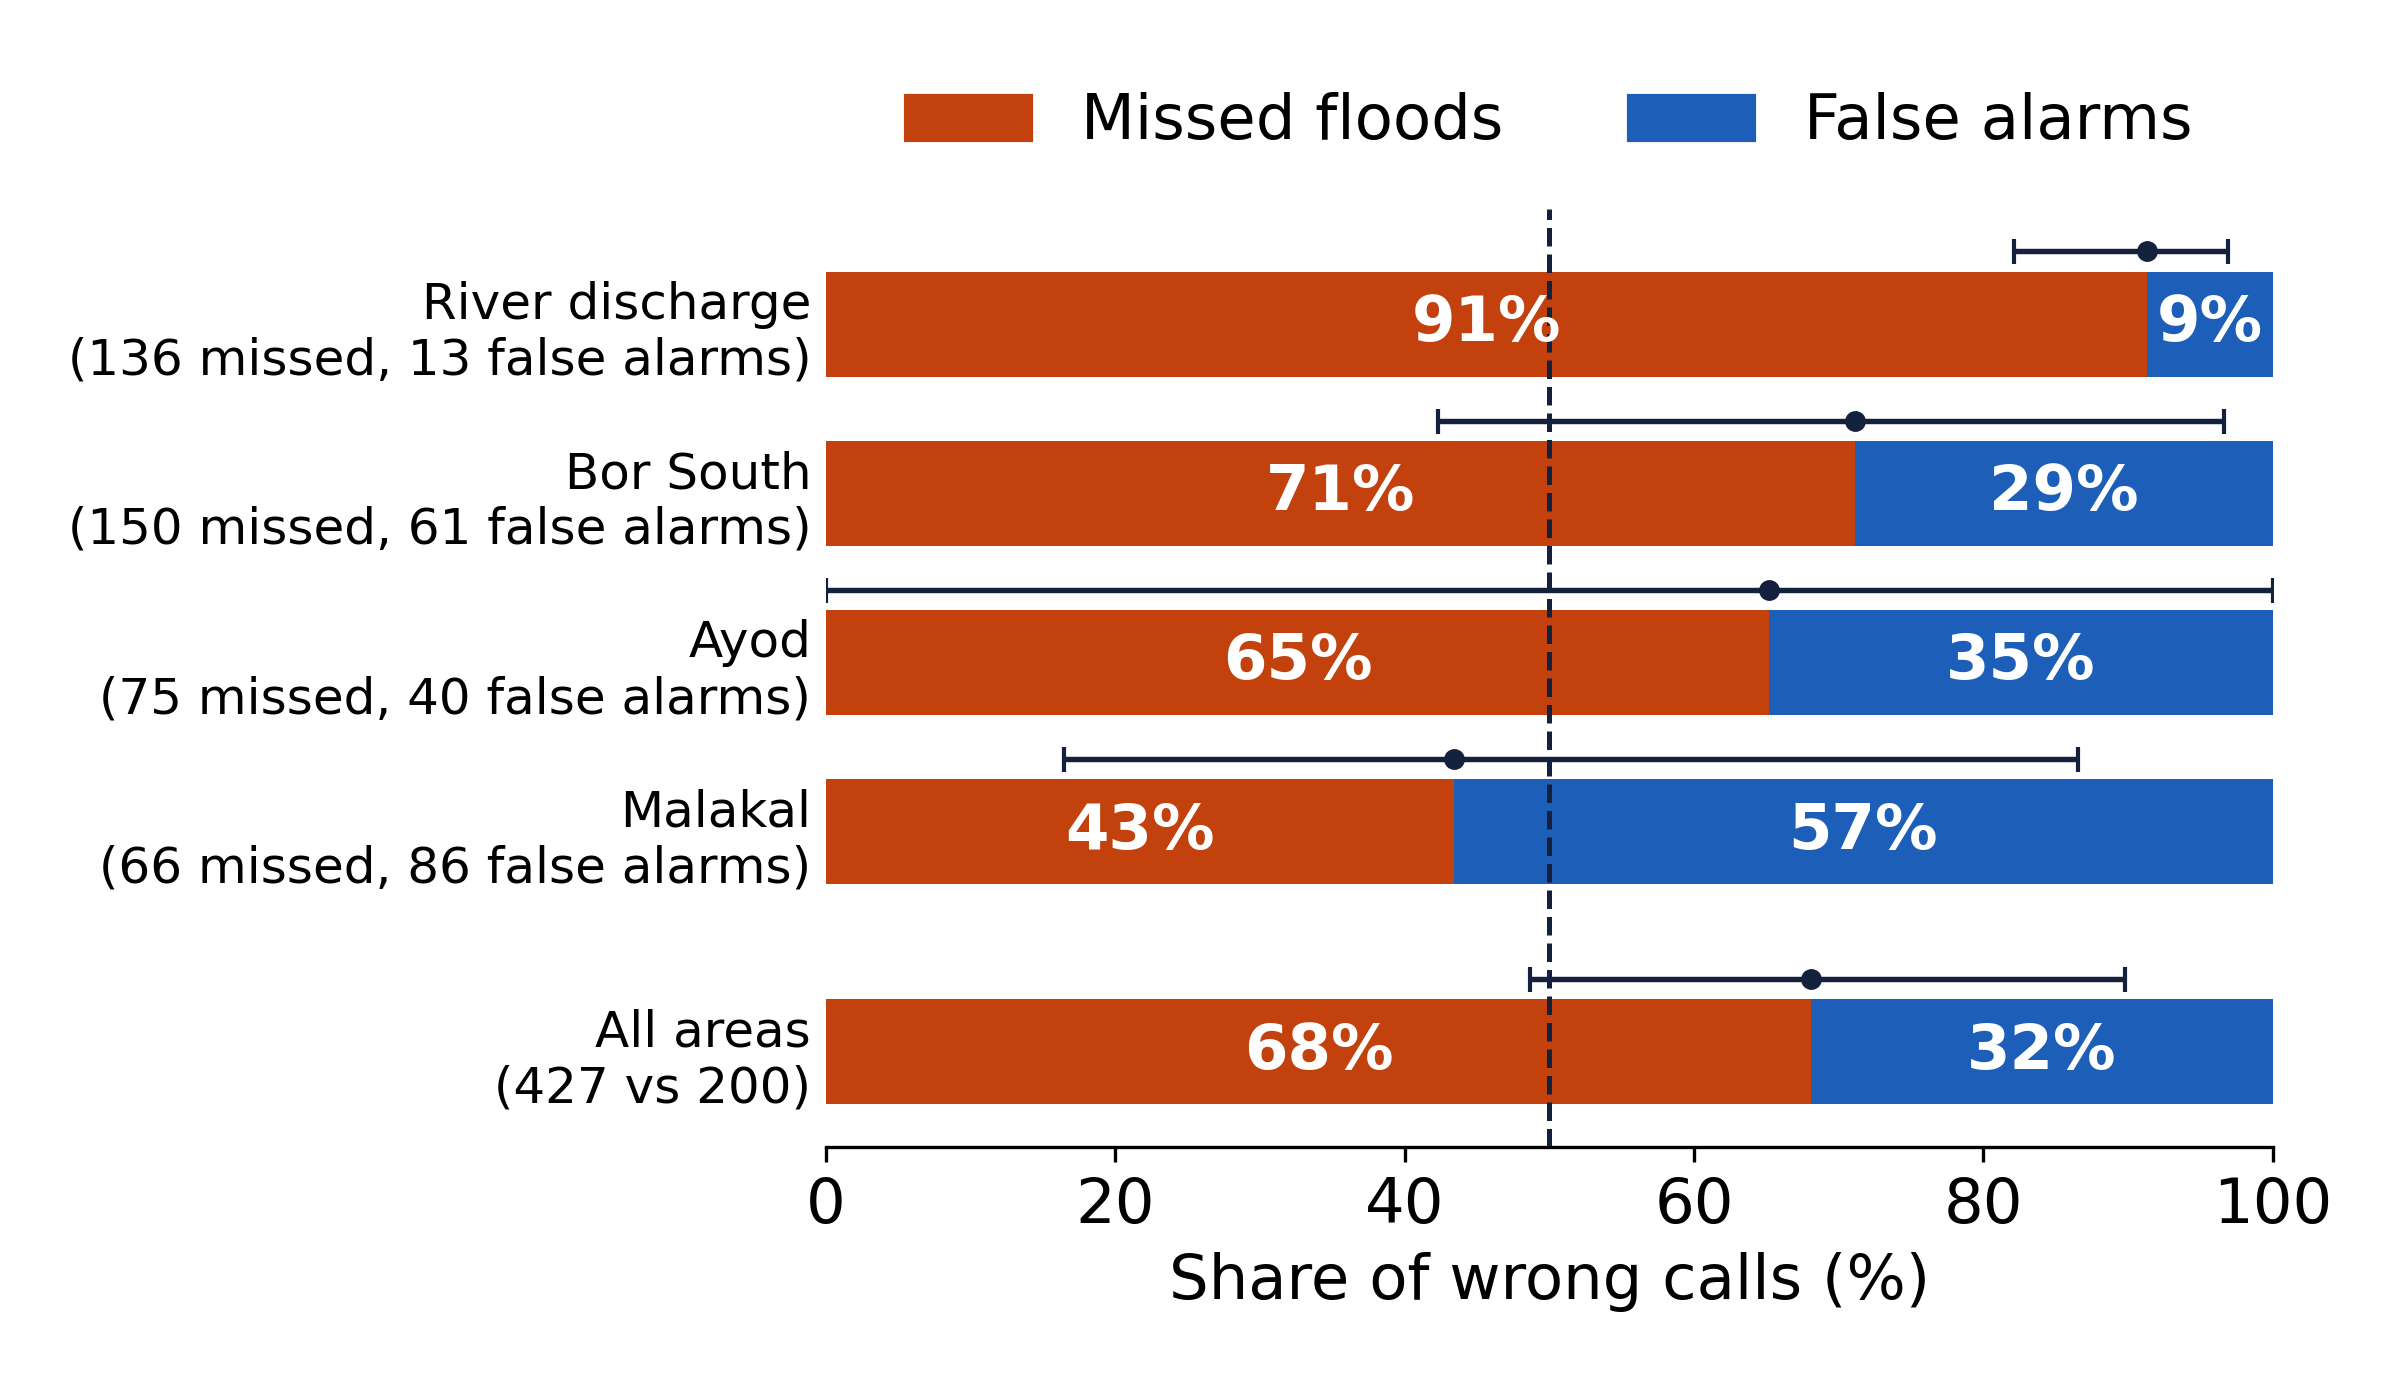

In [7]:
pool = read("sle_pooled.csv").set_index("scope")
overall = pool.loc["all sites, all leads"]
print(f"Overall: {int(overall.FN)} missed floods vs {int(overall.FP)} false alarms; "
      f"{overall.miss_share:.0%} of wrong forecasts are misses (95% range {overall.lo:.0%} to {overall.hi:.0%}).")
summary = pool.drop(index="all sites, all leads").copy()
summary.index = summary.index.map(AREA)
summary["false_alarm_share"] = 1 - summary.miss_share
display(summary[["FN", "FP", "miss_share", "lo", "hi", "false_alarm_share"]].round(2))
fig_path = V2 / "poster_figures" / "fig_misses_vs_false_alarms.png"
if fig_path.exists():
    display(Image(filename=str(fig_path), width=600))

### Cost simulator (poster section 04, Figure 4)

Total cost = missed floods x ratio + false alarms. The ratio is an assumption set by the stakeholder (default 5); the dashboard lets users change it. Below, the same calculation at one month ahead for three ratios.

Ratio 2: total cost at 1 month ahead (lower is better)


method,model (ar+lake),rule: 12-mo mean anomaly,rule: last anomaly persists,rule: seasonal average
area,,,,
Ayod,25.0,27.0,10.0,78.0
Bor South,70.0,63.0,44.0,78.0
Malakal,41.0,31.0,32.0,42.0
River discharge,54.0,45.0,35.0,54.0


Ratio 5: total cost at 1 month ahead (lower is better)


method,model (ar+lake),rule: 12-mo mean anomaly,rule: last anomaly persists,rule: seasonal average
area,,,,
Ayod,52.0,54.0,22.0,195.0
Bor South,151.0,99.0,80.0,192.0
Malakal,80.0,49.0,62.0,99.0
River discharge,132.0,102.0,71.0,123.0


Ratio 10: total cost at 1 month ahead (lower is better)


method,model (ar+lake),rule: 12-mo mean anomaly,rule: last anomaly persists,rule: seasonal average
area,,,,
Ayod,97.0,99.0,42.0,390.0
Bor South,286.0,159.0,140.0,382.0
Malakal,145.0,79.0,112.0,194.0
River discharge,262.0,197.0,131.0,238.0


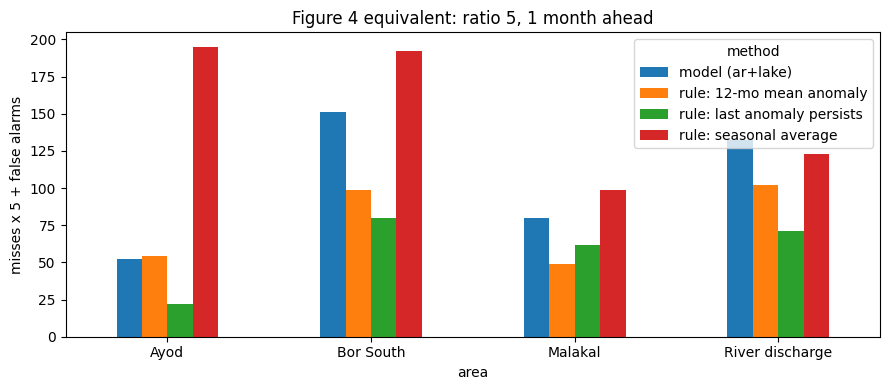

In [8]:
def total_cost(lead, ratio):
    """Total cost per area and method at one lead time for a given miss-to-false-alarm ratio."""
    d = conf[conf.lead == lead].copy()
    d["cost"] = d.FN * ratio + d.FP
    d["area"] = d.target.map(AREA)
    return d.pivot_table(index="area", columns="method", values="cost")

for ratio in (2, 5, 10):
    print(f"Ratio {ratio}: total cost at 1 month ahead (lower is better)")
    display(total_cost(1, ratio).round(0))

total_cost(1, 5).plot.bar(figsize=(9, 4), rot=0)
plt.ylabel("misses x 5 + false alarms")
plt.title("Figure 4 equivalent: ratio 5, 1 month ahead")
plt.tight_layout()
plt.show()

## 5. Does the model beat simple rules? (takeaway 1)

Skill compares the forecast error (RMSE) of the model with a simple rule. Positive means the model has smaller error. Test years from 2020 on.

In [9]:
skill = read("skill_v2.csv")
view = skill[(skill.scope == "post") & (skill.featureset == "ar+lake") & (skill.model == "ridge")].copy()
view["area"] = view.target.map(AREA)
cols = ["skill_vs_persist_anom", "skill_vs_trail12_anom"]
print("skill vs 'next month looks like last month' (persist) and vs the 12-month average (trail12):")
display(view.pivot_table(index="area", columns="lead", values=cols).round(2))

skill vs 'next month looks like last month' (persist) and vs the 12-month average (trail12):


skill_vs_persist_anom                          \
lead                                1     2     3     4     6   
area                                                            
Ayod                            -1.37 -0.42 -0.10  0.08  0.20   
Bor South                       -0.19 -0.10 -0.19  0.11  0.26   
Malakal                         -1.18 -0.00  0.33  0.46  0.50   
River discharge                 -1.29 -0.21  0.18  0.35  0.50   

                skill_vs_trail12_anom                          
lead                                1     2     3     4     6  
area                                                           
Ayod                             0.12 -0.03 -0.08 -0.01  0.13  
Bor South                       -0.28 -0.46 -0.58 -0.57 -0.44  
Malakal                          0.20  0.10  0.06  0.02 -0.05  
River discharge                  0.27  0.12  0.09  0.08  0.15

## 6. Limitations to keep in mind

- **Short record after the shift.** Flooding changed around 2020, and only about six test years follow it, so uncertainty ranges are wide and the shift needs confirming.
- **One fixed alert level.** We counted errors at one alert level. Moving that level trades missed floods for false alarms, and we did not tune it.
- **The cost ratio is an assumption.** The default of 5 is within ranges reported for flood early warning elsewhere, not measured for South Sudan.
- **No ground validation.** Flood extent is derived from remote-sensing masks and was not checked against local observations or community reports.
- **Land cover.** The land-cover data was too poor to say which anticipatory action fits each area.
- **Not an operational system.** The results support discussion of thresholds and trade-offs and need further validation before use in decisions.

To explore the results interactively, start the dashboard from the project root: `streamlit run flood_drivers/dashboard/app.py`.